# Flight delays — small EDA
Dataset: USDOT 2015 domestic flights (`usdot/flight-delays` on Kaggle) — `flights`, `airlines`, `airports`.

Grain:
- `flights`: 1 row per scheduled flight (airline, flight number, date, origin → destination)
- `airlines`: 1 row per `IATA_CODE`
- `airports`: 1 row per `IATA_CODE`

In [57]:
import kagglehub
import os
import pandas as pd
# Download latest version
path = kagglehub.dataset_download("usdot/flight-delays")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\ferna\.cache\kagglehub\datasets\usdot\flight-delays\versions\1


In [58]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

# Airport columns mix IATA codes and numeric IDs (see findings) -> force str
dfs = {
    "flights": pd.read_csv(os.path.join(path, "flights.csv"),
                           dtype={"ORIGIN_AIRPORT": str, "DESTINATION_AIRPORT": str}),
    "airlines": pd.read_csv(os.path.join(path, "airlines.csv")),
    "airports": pd.read_csv(os.path.join(path, "airports.csv")),
}
flights = dfs["flights"]
flights["DATE"] = pd.to_datetime(flights[["YEAR", "MONTH", "DAY"]])
for name, df in dfs.items():
    print(f"{name:9s} {df.shape}")

flights   (5819079, 32)
airlines  (14, 2)
airports  (322, 7)


## 1. Overview: dtypes, nulls, duplicates

In [59]:
overview = pd.DataFrame({
    "dtype": flights.dtypes.astype(str),
    "null_pct": flights.isna().mean().mul(100).round(2),
    "n_unique": flights.nunique(),
})
print("Date range:", flights["DATE"].min().date(), "->", flights["DATE"].max().date())
print("Duplicate rows:", flights.duplicated().sum())
key = ["DATE", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT", "SCHEDULED_DEPARTURE"]
print("Duplicate flight keys:", flights.duplicated(key).sum())
overview

Date range: 2015-01-01 -> 2015-12-31
Duplicate rows: 0
Duplicate flight keys: 1


,dtype,null_pct,n_unique
YEAR,int64,0.00,1
MONTH,int64,0.00,12
DAY,int64,0.00,31
DAY_OF_WEEK,int64,0.00,7
AIRLINE,str,0.00,14
FLIGHT_NUMBER,int64,0.00,6952
TAIL_NUMBER,str,0.25,4897
ORIGIN_AIRPORT,str,0.00,628
DESTINATION_AIRPORT,str,0.00,629
SCHEDULED_DEPARTURE,int64,0.00,1321


In [60]:
flights[["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "AIR_TIME", "DISTANCE"]].describe().round(1)

,DEPARTURE_DELAY,ARRIVAL_DELAY,TAXI_OUT,AIR_TIME,DISTANCE
count,5732926.0,5714008.0,5730032.0,5714008.0,5819079.0
mean,9.4,4.4,16.1,113.5,822.4
std,37.1,39.3,8.9,72.2,607.8
min,-82.0,-87.0,1.0,7.0,21.0
25%,-5.0,-13.0,11.0,60.0,373.0
50%,-2.0,-5.0,14.0,94.0,647.0
75%,7.0,8.0,19.0,144.0,1062.0
max,1988.0,1971.0,225.0,690.0,4983.0


## 2. Key relationships
Do all flight airline/airport codes exist in the lookup tables?

In [61]:
airline_orphans = ~flights["AIRLINE"].isin(dfs["airlines"]["IATA_CODE"])
print("Flights with unknown airline:", airline_orphans.sum())

origin_orphans = ~flights["ORIGIN_AIRPORT"].isin(dfs["airports"]["IATA_CODE"])
print(f"Flights with unknown origin airport: {origin_orphans.sum():,} ({origin_orphans.mean():.1%})")
print("Months affected:", sorted(flights.loc[origin_orphans, "MONTH"].unique()))
print("Example codes:", flights.loc[origin_orphans, "ORIGIN_AIRPORT"].unique()[:5])
print("Airports with missing lat/lon:",
      dfs["airports"].loc[dfs["airports"]["LATITUDE"].isna(), "IATA_CODE"].tolist())

Flights with unknown airline: 0
Flights with unknown origin airport: 486,165 (8.4%)
Months affected: [np.int64(10)]
Example codes: <StringArray>
['14747', '14771', '12889', '12892', '14869']
Length: 5, dtype: str
Airports with missing lat/lon: ['ECP', 'PBG', 'UST']


## 2b. Recover October airport codes
`airports` only has IATA codes, so joining October flights to it directly matches 0 rows. The numeric codes are BTS airport IDs. To infer the mapping from the data:
1. **Pass 1:** the same (airline, flight number, scheduled departure, distance) flies the same route in Sep/Nov. Each such match casts a vote for numeric→IATA, separately for origin and destination.
2. **Pass 2:** for codes that pass 1 didn't map, match (airline, distance, already-mapped other endpoint) against all other months. IATA codes already taken are excluded because the mapping is one-to-one.

In [62]:
route = ["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]
is_oct = flights["MONTH"] == 10
num_codes = set(pd.unique(flights.loc[is_oct, route].values.ravel()))

def vote(pairs):
    """pairs[num, iata] -> most-voted iata per num, with vote share."""
    vc = pairs.value_counts().rename("n").reset_index()
    vc["share"] = vc["n"] / vc.groupby("num")["n"].transform("sum")
    return vc.sort_values("n", ascending=False).drop_duplicates("num").set_index("num")

def endpoint_pairs(merged, cols):
    return pd.concat([merged[[f"{c}_num", f"{c}_iata"]].set_axis(["num", "iata"], axis=1) for c in cols])

# Pass 1: same scheduled flight in Sep/Nov
key1 = ["AIRLINE", "FLIGHT_NUMBER", "SCHEDULED_DEPARTURE", "DISTANCE"]
oct1 = flights.loc[is_oct, key1 + route].drop_duplicates()
ref1 = flights.loc[flights["MONTH"].isin([9, 11]), key1 + route].drop_duplicates()
map1 = vote(endpoint_pairs(oct1.merge(ref1, on=key1, suffixes=("_num", "_iata")), route))

# Pass 2: unmapped codes via airline + distance + the mapped other endpoint
key2 = ["AIRLINE", "DISTANCE"]
unmapped = num_codes - set(map1.index)
oct2 = flights.loc[is_oct, key2 + route].drop_duplicates()
ref2 = flights.loc[~is_oct, key2 + route].drop_duplicates()
pairs2 = []
for unk, other in [route, route[::-1]]:
    q = oct2[oct2[unk].isin(unmapped)].copy()
    q[other] = q[other].map(map1["iata"])
    pairs2.append(endpoint_pairs(q.merge(ref2, on=key2 + [other], suffixes=("_num", "_iata")), [unk]))
pairs2 = pd.concat(pairs2)
map2 = vote(pairs2[~pairs2["iata"].isin(map1["iata"])])

code_map = pd.concat([map1.assign(pass_no=1), map2.assign(pass_no=2)])
print(f"Numeric codes: {len(num_codes)} | pass 1: {len(map1)} | pass 2: {len(map2)}")
print("Min vote share:", code_map["share"].min().round(3))
assert set(code_map.index) == num_codes, num_codes - set(code_map.index)
assert code_map["iata"].is_unique
assert code_map["iata"].isin(dfs["airports"]["IATA_CODE"]).all()

# Sanity check against known BTS airport IDs
known = {"10397": "ATL", "13930": "ORD", "12892": "LAX", "11298": "DFW", "14747": "SEA", "12478": "JFK"}
assert all(code_map.loc[k, "iata"] == v for k, v in known.items())
code_map[code_map["pass_no"] == 2]

Numeric codes: 307 | pass 1: 300 | pass 2: 7
Min vote share: 0.9


,iata,n,share,pass_no
num,,,,
15323,TRI,4,1.0,2
10581,BGR,4,1.0,2
10141,ABR,2,1.0,2
14098,PHF,2,1.0,2
10577,BGM,2,1.0,2
13360,MLB,2,1.0,2
10666,BLI,1,1.0,2


In [63]:
flights["AIRPORT_CODE_INFERRED"] = is_oct.astype(int)
for c in route:
    flights.loc[is_oct, c] = flights.loc[is_oct, c].map(code_map["iata"])

n_before = len(flights)
flights = flights.merge(
    dfs["airports"][["IATA_CODE", "STATE"]].rename(columns={"IATA_CODE": "ORIGIN_AIRPORT", "STATE": "ORIGIN_STATE"}),
    on="ORIGIN_AIRPORT", how="left", validate="many_to_one")
assert len(flights) == n_before
print("Flights with unknown origin after mapping:", flights["ORIGIN_STATE"].isna().sum())
print("Flights with unknown destination after mapping:",
      (~flights["DESTINATION_AIRPORT"].isin(dfs["airports"]["IATA_CODE"])).sum())

Flights with unknown origin after mapping: 0
Flights with unknown destination after mapping: 0


## 3. Cancellations and diversions
Reasons: A = airline/carrier, B = weather, C = National Air System, D = security.

Cancelled: 1.54%   Diverted: 0.26%
CANCELLATION_REASON
Weather            0.543
Airline            0.281
Nat. Air System    0.175
Security           0.000
Name: proportion, dtype: float64


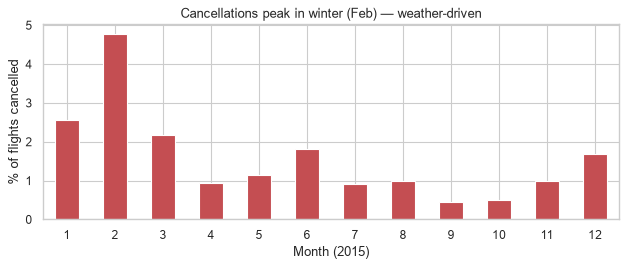

In [64]:
print(f"Cancelled: {flights['CANCELLED'].mean():.2%}   Diverted: {flights['DIVERTED'].mean():.2%}")
reason_map = {"A": "Airline", "B": "Weather", "C": "Nat. Air System", "D": "Security"}
print(flights["CANCELLATION_REASON"].map(reason_map).value_counts(normalize=True).round(3))

cancel_by_month = flights.groupby("MONTH")["CANCELLED"].mean().mul(100)
ax = cancel_by_month.plot(kind="bar", figsize=(8, 3.5), color="C3")
ax.set(title="Cancellations peak in winter (Feb) — weather-driven",
       xlabel="Month (2015)", ylabel="% of flights cancelled")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 4. Arrival delay distribution
Only flights that actually arrived (not cancelled / diverted) have `ARRIVAL_DELAY`. The industry definition of *late* is arrival delay > 15 min.

Arrived flights: 5,714,008 of 5,819,079
Late (>15 min): 17.9%
Arrived early (<0 min): 61.3%
Max arrival delay (min): 1971.0


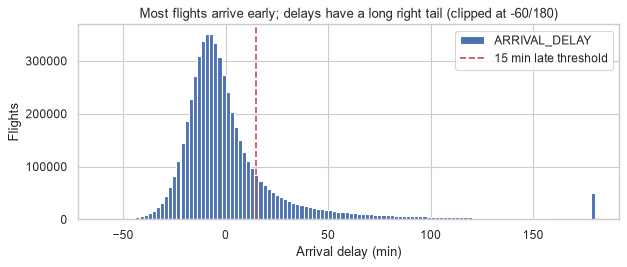

In [65]:
arrived = flights[flights["ARRIVAL_DELAY"].notna()]
print(f"Arrived flights: {len(arrived):,} of {len(flights):,}")
print(f"Late (>15 min): {(arrived['ARRIVAL_DELAY'] > 15).mean():.1%}")
print(f"Arrived early (<0 min): {(arrived['ARRIVAL_DELAY'] < 0).mean():.1%}")
print("Max arrival delay (min):", arrived["ARRIVAL_DELAY"].max())

fig, ax = plt.subplots(figsize=(8, 3.5))
arrived["ARRIVAL_DELAY"].clip(-60, 180).plot(kind="hist", bins=120, ax=ax)
ax.axvline(15, color="C3", ls="--", label="15 min late threshold")
ax.set(title="Most flights arrive early; delays have a long right tail (clipped at -60/180)",
       xlabel="Arrival delay (min)", ylabel="Flights")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Delay by airline, month and hour of day

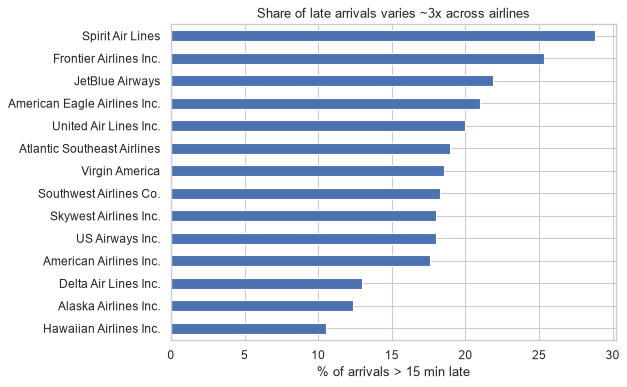

In [66]:
arrived = arrived.assign(LATE=arrived["ARRIVAL_DELAY"] > 15)
airline_names = dfs["airlines"].set_index("IATA_CODE")["AIRLINE"]
late_by_airline = (arrived.groupby("AIRLINE")["LATE"].mean().mul(100)
                   .rename(index=airline_names).sort_values())
ax = late_by_airline.plot(kind="barh", figsize=(8, 5))
ax.set(title="Share of late arrivals varies ~3x across airlines",
       xlabel="% of arrivals > 15 min late", ylabel="")
plt.tight_layout(); plt.show()

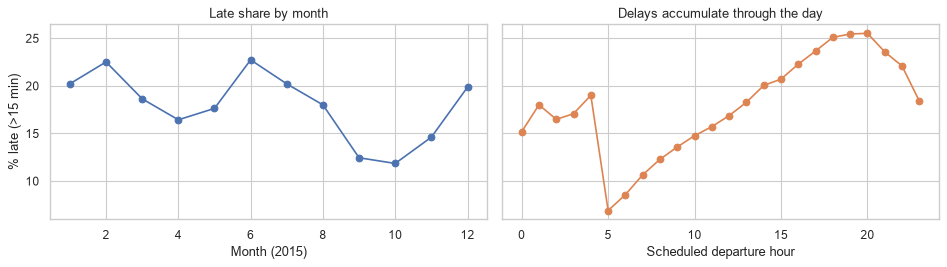

In [67]:
arrived["DEP_HOUR"] = arrived["SCHEDULED_DEPARTURE"] // 100
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
arrived.groupby("MONTH")["LATE"].mean().mul(100).plot(marker="o", ax=axes[0])
axes[0].set(title="Late share by month", xlabel="Month (2015)", ylabel="% late (>15 min)")
arrived.groupby("DEP_HOUR")["LATE"].mean().mul(100).plot(marker="o", ax=axes[1], color="C1")
axes[1].set(title="Delays accumulate through the day", xlabel="Scheduled departure hour")
plt.tight_layout(); plt.show()

## 6. Delay causes
Cause columns are only filled for flights with arrival delay ≥ 15 min.

Cause filled & arrival delay >= 15: True


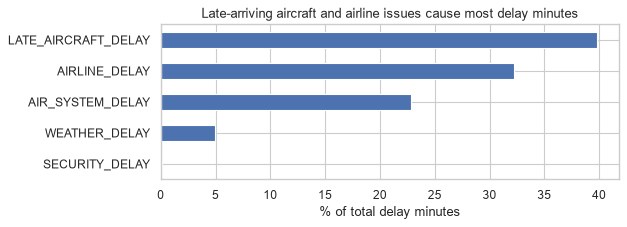

In [68]:
cause_cols = ["AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY",
              "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]
has_cause = flights[cause_cols].notna().all(axis=1)
print("Cause filled & arrival delay >= 15:",
      (flights.loc[has_cause, "ARRIVAL_DELAY"] >= 15).all())
cause_share = flights[cause_cols].sum().div(flights[cause_cols].sum().sum()).mul(100).sort_values()
ax = cause_share.plot(kind="barh", figsize=(8, 3))
ax.set(title="Late-arriving aircraft and airline issues cause most delay minutes",
       xlabel="% of total delay minutes", ylabel="")
plt.tight_layout(); plt.show()

## 7. Busiest airports

In [69]:
top = (arrived.groupby("ORIGIN_AIRPORT")
       .agg(flights=("LATE", "size"), late_pct=("LATE", "mean"),
            mean_dep_delay=("DEPARTURE_DELAY", "mean"))
       .nlargest(10, "flights"))
top["late_pct"] = top["late_pct"].mul(100).round(1)
top["mean_dep_delay"] = top["mean_dep_delay"].round(1)
top.join(dfs["airports"].set_index("IATA_CODE")[["CITY", "STATE"]])

,flights,late_pct,mean_dep_delay,CITY,STATE
ORIGIN_AIRPORT,,,,,
ATL,376015,15.2,8.9,Atlanta,GA
ORD,304120,22.4,13.2,Chicago,IL
DFW,253233,20.3,11.0,Dallas-Fort Worth,TX
DEN,211479,20.8,11.3,Denver,CO
LAX,209631,19.6,10.2,Los Angeles,CA
SFO,159585,19.2,10.7,San Francisco,CA
PHX,158436,17.6,8.3,Phoenix,AZ
IAH,157110,20.0,11.1,Houston,TX
LAS,144586,19.4,10.5,Las Vegas,NV


## 8. Findings
**Data quality**
1. **October airport codes are numeric:** every October flight (486,165 rows, 8.4%) uses 5-digit BTS airport IDs (e.g. `14747`) instead of IATA codes, so a direct join to `airports` matches 0 rows. Section 2b recovers all 307 IDs from flights that fly the same schedule in other months. Every inferred code exists in `airports`, the mapping is one-to-one, and known IDs check out. After mapping, every flight joins to `airports`. October rows are flagged with `AIRPORT_CODE_INFERRED`.
2. Read airport columns as `str`. Otherwise pandas raises a mixed-dtype warning because of (1).
3. `airports` lacks lat/lon for 3 codes (ECP, PBG, UST).
4. There are no full-row duplicates. One flight key (date, airline, flight no., origin, sched. dep.) is duplicated.
5. Nulls are structural, not random:
   - Departure, arrival and air-time columns (~1.5–1.8%) are null because the flight was cancelled (1.54%) or diverted (0.26%). Diverted flights never have an `ARRIVAL_DELAY`.
   - `CANCELLATION_REASON` is null unless the flight was cancelled.
   - The 5 delay-cause columns (81.7% null) are filled only when arrival delay ≥ 15 min.
6. Delays have heavy tails, up to ~33 h (1,971 min). Many early arrivals (min −87) reflect padded schedules.
7. Times are stored as HHMM integers (`SCHEDULED_DEPARTURE=5` means 00:05). Convert them before computing durations across midnight.

**Patterns**
- 17.9% of arrived flights were late (>15 min). 61.3% arrived early.
- **Airline:** late share ranges from 10.5% (Hawaiian) to 28.8% (Spirit).
- **Season:** Cancellations peak in February (4.8%), and weather causes 54% of all cancellations. Late share is highest in Jun and Feb (~23%) and lowest in Sep–Oct (~12%).
- **Time of day:** late share climbs from ~7% at 5 am to ~25% at 6–8 pm because delays propagate through the day. Late-aircraft delay makes up 40% of delay minutes, airline 32%, air system 23%, weather 5%.
- **Airports:** Among the busiest, ORD (22.4%) and DEN (20.8%) are the most delay-prone. ATL and MSP are the least (15.2%). All 12 months are included now that October codes are mapped.

**Candidate target:** `ARRIVAL_DELAY > 15` (balance ~18/82). The signals known at schedule time are airline, month, departure hour, origin and route. Do **not** use departure delay, taxi, wheels or cause columns as features: they are only known after departure.